<a href="https://colab.research.google.com/github/SkrybaOtis/InzOp/blob/main/SystemyAI_Lab7_softmax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Systemy AI – Laboratorium 7
## Zadanie: klasyfikator softmax w PyTorch – pingwiny

Napisz samodzielnie w PyTorch klasyfikator softmax, który rozpoznaje **gatunek pingwina** (Adelie, Chinstrap, Gentoo) na podstawie **dwóch** cech: długości i wysokości dzioba. Znasz te dane z Lab 4 – tym razem nie używasz gotowego `fit`, tylko sam(a) piszesz pętlę uczenia. Wzoruj się na notatniku `SystemyAI_Lab7_wzor.ipynb`.

Dwie cechy wybraliśmy celowo: wynik da się narysować na płaszczyźnie, a zadanie nie jest trywialne (Adelie i Chinstrap częściowo na siebie nachodzą).

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane → tensory
1. Wczytaj `sns.load_dataset("penguins")`, zostaw wiersze bez braków w `bill_length_mm`, `bill_depth_mm`, `species`.
2. Zamień gatunki na liczby: `gatunki = ["Adelie", "Chinstrap", "Gentoo"]` → 0, 1, 2.
3. Podział **trzyczęściowy** (dwa razy `train_test_split`, `stratify`, `random_state=42`): najpierw 20% na test, potem z reszty 25% na walidację. Wyjdzie 204 / 69 / 69.
4. `StandardScaler` dopasowany **tylko** na train; przekształć wszystkie trzy zbiory.
5. Tensory: `X_tr`, `X_va`, `X_te` (`float32`) oraz `y_tr`, `y_va`, `y_te` (`long`).

Zbiór walidacyjny posłuży do krzywych uczenia i wyboru learning rate, testowy – raz, na końcu.

In [ ]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

cechy = ["bill_length_mm", "bill_depth_mm"]
df = sns.load_dataset("penguins").dropna(subset=cechy + ["species"])


gatunki = ["Adelie", "Chinstrap", "Gentoo"]
y = df["species"].map({g: i for i, g in enumerate(gatunki)}).values
X = df[cechy].values

X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=42)
print("rozmiary train / val / test:", len(X_train), len(X_val), len(X_test))

scaler = StandardScaler().fit(X_train)

X_tr = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
X_va = torch.tensor(scaler.transform(X_val),   dtype=torch.float32)
X_te = torch.tensor(scaler.transform(X_test),  dtype=torch.float32)
y_tr = torch.tensor(y_train, dtype=torch.long)
y_va = torch.tensor(y_val,   dtype=torch.long)
y_te = torch.tensor(y_test,  dtype=torch.long)

rozmiary train / val / test: 204 69 69


In [ ]:
# TEST
assert X_tr.shape == (204, 2) and X_va.shape == (69, 2) and X_te.shape == (69, 2)
assert X_tr.dtype == torch.float32 and y_tr.dtype == torch.long
assert set(y_tr.tolist()) == {0, 1, 2}
assert torch.allclose(X_tr.mean(dim=0), torch.zeros(2), atol=1e-5), "Standaryzacja dopasowana na train"
print("1 OK")

1 OK


---
## 2. Model i strata przed uczeniem
1. `torch.manual_seed(0)`, potem `model = nn.Linear(2, 3)` i `loss_fn = nn.CrossEntropyLoss()`.
2. Policz `loss0` – stratę na zbiorze treningowym **przed** uczeniem (`.item()`).
3. Policz `p0` – prawdopodobieństwa (softmax) dla pierwszych 3 pingwinów treningowych i wypisz je.

In [ ]:
torch.manual_seed(0)
model = nn.Linear(2, 3)
loss_fn = nn.CrossEntropyLoss()

with torch.no_grad():  # no_grad: tylko liczymy, nie śledzimy gradientów (szybciej)
    loss0 = loss_fn(model(X_tr), y_tr).item()
    p0 = torch.softmax(model(X_tr[:3]), dim=1)

print(f"loss0 = {loss0:.3f}   (dla porównania ln 3 = {math.log(3):.3f})")
print("prawdopodobieństwa (kolumny: Adelie, Chinstrap, Gentoo):")
print(p0.numpy().round(3))
print("prawdziwe gatunki:", [gatunki[i] for i in y_tr[:3].tolist()])

loss0 = 1.530   (dla porównania ln 3 = 1.099)
prawdopodobieństwa (kolumny: Adelie, Chinstrap, Gentoo):
[[0.194 0.552 0.254]
 [0.33  0.384 0.286]
 [0.414 0.237 0.349]]
prawdziwe gatunki: ['Adelie', 'Adelie', 'Adelie']


In [ ]:
# TEST
assert 0.8 < loss0 < 2.0
assert torch.allclose(p0.sum(dim=1), torch.ones(3))
print("2 OK")

2 OK


*Twoja odpowiedź:*

Model, który dla każdego pingwina daje wszystkim trzem gatunkom prawdopodobieństwo 1/3, ma stratę dokładnie ln 3 ≈ 1.10. Dlaczego? Czy twoja `loss0` jest blisko tej wartości?


> Strata dla pojedynczego pingwina to `−ln(prawdopodobieństwo prawdziwego gatunku)`. Jeśli model daje każdemu gatunkowi `1/3`, to prawdziwemu gatunkowi też daje `1/3`, więc strata wynosi `−ln(1/3) = ln 3`

> Moja `loss0` jak wypisano w komórce powyżej obok `ln 3` jest blisko tej wartości (chociaż zasadniczo blisko to pojęcie względne)

---
## 3. Pętla uczenia
Napisz funkcję `train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va)`, która:
- ustawia `torch.manual_seed(seed)` i tworzy **nowy** `nn.Linear(2, 3)`, `CrossEntropyLoss` i `optim.SGD(..., lr=lr)`,
- uczy model mini-batchami (`DataLoader` z `shuffle=True`) przez `epochs` epok,
- po każdej epoce zapisuje w słowniku `historia` trzy listy: `"train loss"` (na `X`), `"val loss"` i `"val acc"` (na `X_val`); parametry `X` i `X_val` przydadzą się w punkcie 5,
- zwraca `(model, historia)`.

Uruchom ją dla `lr=0.1` (`model_01, hist_01`) i narysuj dwa wykresy: straty train/val oraz accuracy val w funkcji epoki.

lr=0.1: val loss = 0.149, val acc = 0.971


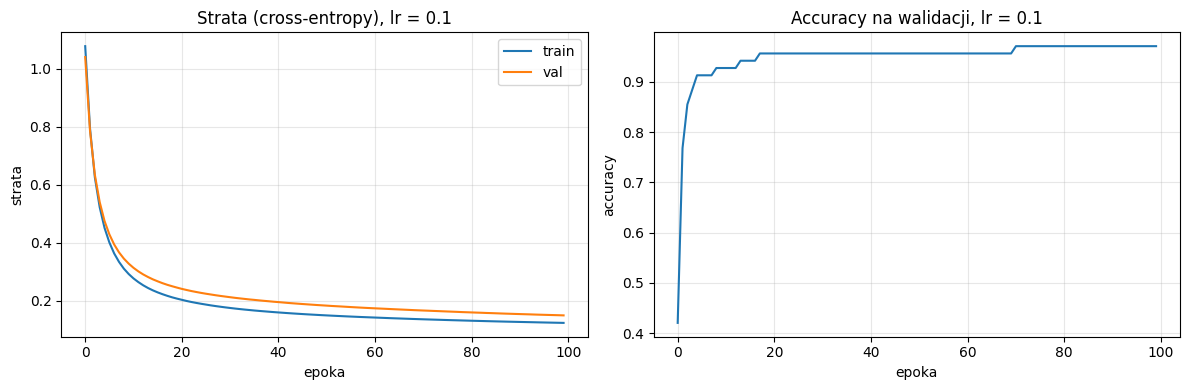

In [ ]:
def train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va):
    """Uczy model softmax (nn.Linear(2, 3)) i zwraca (model, historia)."""
    torch.manual_seed(seed)
    model = nn.Linear(2, 3)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)

    loader = DataLoader(TensorDataset(X, y_tr), batch_size=batch_size, shuffle=True)

    historia = {"train loss": [], "val loss": [], "val acc": []}
    for epoka in range(epochs):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            historia["train loss"].append(loss_fn(model(X), y_tr).item())
            logity_val = model(X_val)
            historia["val loss"].append(loss_fn(logity_val, y_va).item())
            trafione = (logity_val.argmax(dim=1) == y_va).float()
            historia["val acc"].append(trafione.mean().item())
    return model, historia


model_01, hist_01 = train(lr=0.1)
print(f"lr=0.1: val loss = {hist_01['val loss'][-1]:.3f}, val acc = {hist_01['val acc'][-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_01["train loss"], label="train")
axes[0].plot(hist_01["val loss"], label="val")
axes[0].set_title("Strata (cross-entropy), lr = 0.1")
axes[0].set_xlabel("epoka"); axes[0].set_ylabel("strata"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(hist_01["val acc"])
axes[1].set_title("Accuracy na walidacji, lr = 0.1")
axes[1].set_xlabel("epoka"); axes[1].set_ylabel("accuracy"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# TEST
assert set(hist_01) == {"train loss", "val loss", "val acc"} and len(hist_01["val acc"]) == 100
assert hist_01["train loss"][-1] < hist_01["train loss"][0], "Strata powinna maleć"
assert hist_01["val acc"][-1] > 0.9
print("3 OK")

3 OK


---
## 4. Learning rate
Naucz model dla `lr` ∈ {0.001, 0.01, 0.1, 1.0}. Na jednym wykresie narysuj krzywe **straty treningowej** dla wszystkich czterech wartości, a wyniki końcowe (`val loss`, `val acc` po 100 epokach) zbierz w `pd.DataFrame` o nazwie `wyniki_lr` (indeks: wartości lr).

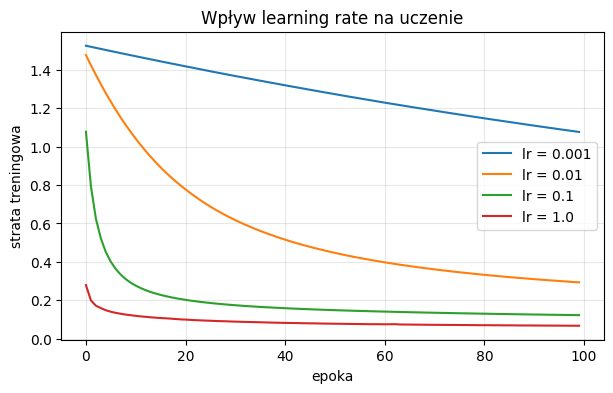

,val loss,val acc
0.001,1.038211,0.420290
0.010,0.329397,0.927536
0.100,0.149183,0.971014
1.000,0.072390,0.971014


In [ ]:
lrs = [0.001, 0.01, 0.1, 1.0]
modele, historie = {}, {}

fig, ax = plt.subplots(figsize=(7, 4))
for lr in lrs:
    modele[lr], historie[lr] = train(lr)
    ax.plot(historie[lr]["train loss"], label=f"lr = {lr}")
ax.set_xlabel("epoka"); ax.set_ylabel("strata treningowa")
ax.set_title("Wpływ learning rate na uczenie"); ax.legend(); ax.grid(alpha=0.3)
plt.show()


wyniki_lr = pd.DataFrame(
    {"val loss": [historie[lr]["val loss"][-1] for lr in lrs],
     "val acc":  [historie[lr]["val acc"][-1] for lr in lrs]},
    index=lrs,
)
wyniki_lr

In [ ]:
# TEST
assert list(wyniki_lr.index) == [0.001, 0.01, 0.1, 1.0]
assert wyniki_lr.loc[0.001, "val loss"] > wyniki_lr.loc[0.1, "val loss"]
print("4 OK")

4 OK


*Twoja odpowiedź:*

Co widać dla lr = 0.001? Który learning rate wybierasz i na podstawie którego zbioru?

> Dla lr = 0.001 strata maleje tak wolno, że na koniec model i tak jest mocno niedouczony.

> Wybieram lr = 1.0 na podstawie zbioru walidacyjnego.

---
## 5. Co daje standaryzacja?
Utwórz `X_tr_raw` i `X_va_raw` – tensory **bez** standaryzacji (surowe milimetry z `X_train`, `X_val`) i naucz model z `lr=0.1`: `train(0.1, X=X_tr_raw, X_val=X_va_raw)`. Porównaj końcową stratę i accuracy z wynikiem z punktu 3. Wynik zapisz w `hist_raw`.

               val loss   val acc
standaryzacja:    0.149   0.971
surowe dane:     29.097   0.797


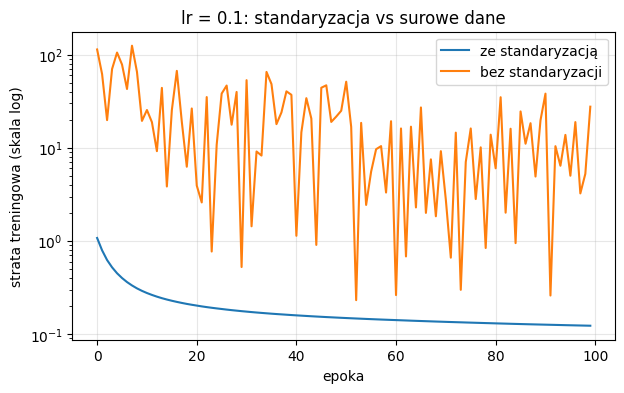

In [ ]:
X_tr_raw = torch.tensor(X_train, dtype=torch.float32)
X_va_raw = torch.tensor(X_val,   dtype=torch.float32)

_, hist_raw = train(0.1, X=X_tr_raw, X_val=X_va_raw)

print("               val loss   val acc")
print(f"standaryzacja:  {hist_01['val loss'][-1]:7.3f}   {hist_01['val acc'][-1]:.3f}")
print(f"surowe dane:    {hist_raw['val loss'][-1]:7.3f}   {hist_raw['val acc'][-1]:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist_01["train loss"], label="ze standaryzacją")
ax.plot(hist_raw["train loss"], label="bez standaryzacji")
ax.set_yscale("log"); ax.set_xlabel("epoka"); ax.set_ylabel("strata treningowa (skala log)")
ax.set_title("lr = 0.1: standaryzacja vs surowe dane"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

In [ ]:
# TEST
assert hist_raw["val acc"][-1] < hist_01["val acc"][-1]
print("5 OK")

5 OK


*Twoja odpowiedź:*

Dlaczego bez standaryzacji uczenie idzie tak źle, choć model i dane są te same?

> Bez standaryzacji jest tak źle, bo gradient względem wagi jest proporcjonalny do wartości cechy. Cechy mają różne średnie i skale, co skutkuje tym, że lr nie jest do nich dopasowany (dla jednej za duży, dla innej za mały). Według mnie nieustandaryzowane dane dają za duże gradienty, więc "dno doliny" jest "przeskakiwane" w jedną i drugą stronę, a uczenie wygląda przez to jak szarpanina, zamiast gładko dążyć do celu.

---
## 6. Ocena końcowa i porównanie ze scikit-learn
1. Wybierz model z punktu 4 (wybór na podstawie walidacji) i zapisz go jako `model_koncowy`. Policz `acc_test` – accuracy na **teście**.
2. Naucz `LogisticRegression()` ze scikit-learn na tych samych wystandaryzowanych danych treningowych i policz jej accuracy na teście: `acc_sk`.
3. Wypisz prawdopodobieństwa (softmax) Twojego modelu dla pierwszych 5 pingwinów testowych, z nazwami gatunków i prawdziwym gatunkiem.
4. Narysuj obszary decyzyjne `model_koncowy` na płaszczyźnie (wystandaryzowane cechy) z punktami treningowymi – możesz skopiować funkcję `granica` z wzoru.

wybrany learning rate: 1.0
accuracy na teście:  PyTorch = 0.957   scikit-learn = 0.928
pingwin 0: Adelie: 0.97, Chinstrap: 0.03, Gentoo: 0.00   | prawdziwy gatunek: Adelie
pingwin 1: Adelie: 0.98, Chinstrap: 0.02, Gentoo: 0.00   | prawdziwy gatunek: Adelie
pingwin 2: Adelie: 0.00, Chinstrap: 0.01, Gentoo: 0.99   | prawdziwy gatunek: Gentoo
pingwin 3: Adelie: 0.00, Chinstrap: 0.11, Gentoo: 0.89   | prawdziwy gatunek: Gentoo
pingwin 4: Adelie: 0.09, Chinstrap: 0.91, Gentoo: 0.00   | prawdziwy gatunek: Chinstrap


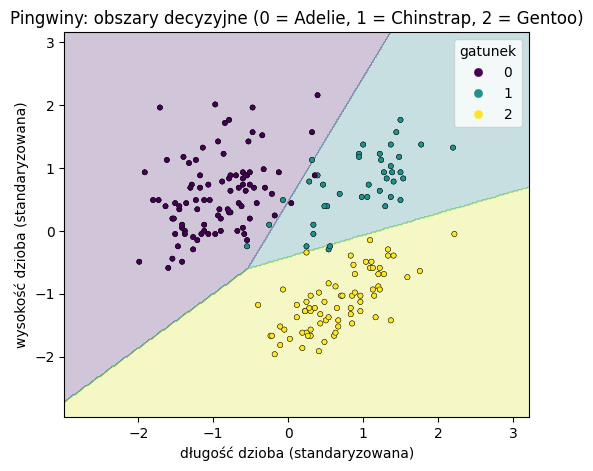

In [ ]:
lr_najlepszy = wyniki_lr["val loss"].idxmin()
print("wybrany learning rate:", lr_najlepszy)

model_koncowy = modele[lr_najlepszy]

with torch.no_grad():
    acc_test = (model_koncowy(X_te).argmax(dim=1) == y_te).float().mean().item()

sk = LogisticRegression().fit(X_tr.numpy(), y_tr.numpy())
acc_sk = sk.score(X_te.numpy(), y_te.numpy())
print(f"accuracy na teście:  PyTorch = {acc_test:.3f}   scikit-learn = {acc_sk:.3f}")

with torch.no_grad():
    p_test = torch.softmax(model_koncowy(X_te[:5]), dim=1)
for i in range(5):
    prawd = ", ".join(f"{g}: {p:.2f}" for g, p in zip(gatunki, p_test[i].tolist()))
    print(f"pingwin {i}: {prawd}   | prawdziwy gatunek: {gatunki[y_te[i].item()]}")

def granica(model, X, y, tytul, softmax=False):
    """Rysuje obszary decyzyjne modelu na płaszczyźnie i punkty danych."""
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
    siatka = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        out = model(siatka)
        Z = out.argmax(dim=1) if softmax else (out > 0).squeeze(1)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(xx, yy, Z.reshape(xx.shape).numpy(), alpha=0.25, cmap="viridis")
    ax.scatter(X[:, 0], X[:, 1], c=y, s=14, cmap="viridis", edgecolors="k", linewidths=0.3)
    ax.set_title(tytul)
    ax.set_xlabel("długość dzioba (standaryzowana)")
    ax.set_ylabel("wysokość dzioba (standaryzowana)")
    sc = ax.scatter(X[:, 0], X[:, 1], c=y, s=14, cmap="viridis", edgecolors="k", linewidths=0.3)
    ax.legend(*sc.legend_elements(), title="gatunek")
    plt.show()

granica(model_koncowy, X_tr.numpy(), y_tr.numpy(),
        "Pingwiny: obszary decyzyjne (0 = Adelie, 1 = Chinstrap, 2 = Gentoo)", softmax=True)

In [ ]:
# TEST
assert 0.85 < acc_test <= 1.0
assert abs(acc_test - acc_sk) <= 0.06, "Ten sam model - wyniki powinny być bardzo podobne"
assert torch.allclose(p_test.sum(dim=1), torch.ones(5))
print("6 OK")

6 OK


*Twoja odpowiedź:*

1. Jak wypada Twój model w porównaniu ze scikit-learn? Czy to zaskakujące?
> Mój model i model scikit-learn mają podobne `accuracy` na teście. Nie jest to dla mnie bardzo zaskakujące ponieważ jak zostało napisane w prezentacji i w teście: to ten sam model. (Różnica to cytując z prezki: `algorytm optymalizacji i regularyzacja (C) w scikit-learn.`).

2. Gdzie leżą błędy modelu na wykresie obszarów decyzyjnych? Czy model liniowy mógłby tu zrobić coś lepiej?
> Błędy modelu na wykresie leżą tam gdzie nakładają się obszary cech gatunków. Model liniowy nic tutaj nie "wyczaruje" bo granice to proste - nie "wygną się" wokół punktów. Pewnie dodanie kolejnych cech tak naprawdę mogłoby poprawić dokładność.


3. Wymień kroki pętli uczenia i powiedz jednym zdaniem, co robi każdy z nich.
> Kroki pętli uczenia:
> - **forward** – `model(xb)` liczy logity;
> - **strata** – `loss_fn(logity, yb)` mierzy, jak bardzo się mylimy;
> - **zero_grad** – kasuje gradienty z poprzedniego kroku (inaczej PyTorch by je dodawał);
> - **backward** – `loss.backward()` liczy nowy gradient straty po wagach;
> - **step** – `optimizer.step()` przesuwa wagi o −lr·gradient, czyli w stronę mniejszej straty.
Całość powtarzamy dla każdej porcji (mini-batcha), a to dla każdej epoki.

---
## 7. Dla chętnych
1. **Batch size:** naucz model z `lr=0.1` dla `batch_size` ∈ {8, 32, 204} (204 = cały zbiór naraz). Porównaj krzywe straty. Który wariant robi najwięcej kroków w epoce? Który uczy się najszybciej w przeliczeniu na epoki?
2. **Adam:** zamień `optim.SGD` na `optim.Adam` (lr = 0.01) i porównaj krzywe z SGD.
3. **Więcej cech:** dodaj `flipper_length_mm` i `body_mass_g` (`nn.Linear(4, 3)`). Ile zyskuje accuracy?